# Duas armadilhas de avaliação no reconhecimento de configurações de mão em Libras

Notebook de reprodução do artigo
**"Two Evaluation Pitfalls in Landmark- and Pixel-Based Hand Configuration Recognition for Brazilian Sign Language"**,
XXI Workshop de Visão Computacional (WVC 2026).

O artigo compara dois ramos de classificação de configurações de mão no conjunto sintético LSWH100:

* **ramo geométrico**: MediaPipe Hands extrai 21 pontos-chave e um MLP classifica o vetor de 63 coordenadas;
* **ramo de pixels**: uma ResNet50 pré-treinada na ImageNet classifica a imagem.

E mostra duas armadilhas de avaliação, ambas favoráveis ao ramo geométrico:

1. **Acurácia condicionada à detecção**: medir a acurácia só nas imagens em que o MediaPipe encontrou a mão.
   Melhorar o detector faz essa acurácia *cair*, enquanto a acurácia fim-a-fim sobe.
2. **Backbone congelado**: avaliar o ramo de pixels com a ResNet50 congelada subestima o ramo em 13 a 26 pontos.

## Como usar

Cada experimento tem uma chave `EXECUTAR_*` na célula de configuração.

* Com as chaves em `False` (padrão), o notebook usa os resultados salvos em `resultados/` e regenera
  **todas as tabelas e figuras do artigo sem precisar do conjunto de dados**. Os MLPs são retreinados de
  qualquer forma, porque levam segundos e partem dos pontos-chave já extraídos (`resultados/landmarks_cond*.npz`).
* Com uma chave em `True`, o experimento correspondente é refeito do zero a partir das imagens do LSWH100
  e o arquivo em `resultados/` é sobrescrito.

| Chave | O que refaz | Precisa do LSWH100 | Tempo aproximado* |
|---|---|---|---|
| `EXECUTAR_DETECCAO` | ablação de pré-processamento do MediaPipe (8 condições) | sim | 2 min |
| `EXECUTAR_LANDMARKS` | extração dos pontos-chave nas condições A e H | sim | 5 min |
| `EXECUTAR_RESNET` | escada C0–C3 da ResNet50 (75 treinos) | sim | 10 h |
| `EXECUTAR_LATENCIA` | latência de inferência | sim (1 imagem) | 1 min |
| `EXECUTAR_VERSOES_MP` | taxa de detecção com outra versão/API do MediaPipe | sim | 1 min |

\* GPU NVIDIA RTX 4050 (6 GB), CPU Intel de 13ª geração.

O LSWH100 está em <https://zenodo.org/records/10635628>. Depois de descompactado, aponte a variável de ambiente
`LSWH100_DIR` (ou a variável `DIR_DATASET` abaixo) para o diretório que contém `train_annotations.coco.json`.

## 0. Configuração

In [1]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')   # silencia os avisos de inicialização do TensorFlow

import collections
import json
import math
import subprocess
import sys
import time

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.stats import binomtest
from sklearn.metrics import classification_report
from tensorflow.keras import layers, models

tf.get_logger().setLevel('ERROR')

# Cresce a memória da GPU sob demanda, em vez de reservar tudo de uma vez.
for _gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(_gpu, True)

# --- chaves de execução (ver tabela acima) ---
EXECUTAR_DETECCAO = False
EXECUTAR_LANDMARKS = False
EXECUTAR_RESNET = False
EXECUTAR_LATENCIA = False
EXECUTAR_VERSOES_MP = False

# --- caminhos ---
DIR_DATASET = os.environ.get('LSWH100_DIR', os.path.join('dados', 'LSWH100'))
DIR_RESULTADOS = 'resultados'
DIR_PRED = os.path.join(DIR_RESULTADOS, 'predicoes')
DIR_FIGURAS = 'figuras'
os.makedirs(DIR_PRED, exist_ok=True)
os.makedirs(DIR_FIGURAS, exist_ok=True)

# --- cenários (Seção III-A) ---
# Os cenários não são aninhados: o de 6 e o de 10 classes partem das mesmas 5 classes base,
# mas acrescentam classes diferentes. A união tem 11 classes, ou seja, 11 x 40 = 440 imagens de teste.
CLASSES_5 = ['S15a', 'S203', 'S19a', 'S19c', 'S185']
CLASSES_6 = CLASSES_5 + ['S177']
CLASSES_10 = CLASSES_5 + ['S1ce', 'S1de', 'S1a3', 'S10e', 'S192']
CENARIOS = {'5_classes': CLASSES_5, '6_classes': CLASSES_6, '10_classes': CLASSES_10}
CLASSES_UNIAO = sorted(set(CLASSES_5) | set(CLASSES_6) | set(CLASSES_10))
NOMES_PT = {'S15a': 'Plana', 'S203': 'Punho', 'S19a': 'Mindinho', 'S19c': 'Mind.+Ind.',
            'S185': 'Ângulo', 'S177': 'Oval'}
SEMENTES = [0, 1, 2, 3, 4]

# Figuras com o tamanho de uma coluna IEEE e vírgula decimal, como no artigo.
plt.rcParams.update({'figure.dpi': 150, 'axes.formatter.use_locale': False})


def virgula(x, casas=3):
    """Formata um número com vírgula decimal (padrão do artigo)."""
    return f'{x:.{casas}f}'.replace('.', ',')


def salvar_json(obj, nome):
    with open(os.path.join(DIR_RESULTADOS, nome), 'w') as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)


def carregar_json(nome):
    with open(os.path.join(DIR_RESULTADOS, nome)) as f:
        return json.load(f)


def wilson(sucessos, total, z=1.96):
    """Intervalo de confiança de Wilson (95%) para uma proporção."""
    if total == 0:
        return (0.0, 0.0)
    p = sucessos / total
    d = 1 + z * z / total
    centro = (p + z * z / (2 * total)) / d
    meia = (z * math.sqrt(p * (1 - p) / total + z * z / (4 * total * total))) / d
    return (max(0.0, centro - meia), min(1.0, centro + meia))


def carregar_split(split, classes=CLASSES_UNIAO):
    """Imagens de um split na ordem das anotações COCO.

    A ordem importa: todos os experimentos usam esta mesma ordem, o que permite
    parear as predições do MLP e da ResNet50 imagem a imagem no teste de McNemar.
    """
    with open(os.path.join(DIR_DATASET, f'{split}_annotations.coco.json')) as f:
        dados = json.load(f)
    cat = {c['id']: c['name'] for c in dados['categories']}
    img_por_id = {i['id']: i for i in dados['images']}
    itens = []
    for a in dados['annotations']:
        codigo = cat.get(a['category_id'])
        info = img_por_id.get(a['image_id'])
        if codigo in classes and info:
            itens.append({'arquivo': info['file_name'], 'codigo': codigo,
                          'orientacao': info['file_name'].split('/')[0], 'bbox': a['bbox']})
    return itens


print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))
print('LSWH100:', 'encontrado' if os.path.isdir(DIR_DATASET) else 'não encontrado (o notebook usa os resultados salvos)')

TensorFlow 2.16.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
LSWH100: não encontrado (o notebook usa os resultados salvos)


## 1. Fluxo experimental (Fig. 1)

O ramo de landmarks descarta as imagens em que o MediaPipe falha. É daí que nasce a diferença entre a acurácia
condicionada à detecção e a acurácia fim-a-fim. O ramo de pixels processa todas as imagens.

![Fig. 1](figuras/diagrama_metodologia.png)

## 2. Armadilha 1: pré-processamento e taxa de detecção do MediaPipe (Seção IV-A, Fig. 2)

O pipeline de referência redimensiona as imagens de 500×500 para 640×480 (distorcendo a razão de aspecto)
e aplica um filtro gaussiano 5×5 antes de chamar o detector. Aqui a taxa de detecção é medida no conjunto de teste
(440 imagens, união das 11 classes) sob oito condições, variando um fator por vez.

Os nomes internos das condições (chaves do JSON) são os do código original; a coluna "Artigo" dá a letra usada no texto.

In [2]:
# chave interna -> (letra no artigo, parâmetros)
CONDICOES = {
    'A_atual':      {'artigo': 'A', 'resize': (640, 480), 'blur': True,  'conf': 0.50, 'recorta_bbox': False,
                     'descricao': '640x480 + desfoque (pipeline de referência)'},
    'B_proporcao':  {'artigo': 'B', 'resize': None, 'blur': True,  'conf': 0.50, 'recorta_bbox': False,
                     'descricao': 'proporção preservada (500x500) + desfoque'},
    'C_sem_blur':   {'artigo': 'C', 'resize': None, 'blur': False, 'conf': 0.50, 'recorta_bbox': False,
                     'descricao': 'B, sem desfoque'},
    'D_conf030':    {'artigo': 'D', 'resize': None, 'blur': False, 'conf': 0.30, 'recorta_bbox': False,
                     'descricao': 'C, confiança 0,30'},
    'D_conf070':    {'artigo': 'E', 'resize': None, 'blur': False, 'conf': 0.70, 'recorta_bbox': False,
                     'descricao': 'C, confiança 0,70'},
    'E_bbox':       {'artigo': 'F', 'resize': None, 'blur': False, 'conf': 0.50, 'recorta_bbox': True, 'margem': 0.10,
                     'descricao': 'C + recorte pela bounding box, margem 10%'},
    'G_bbox_larga': {'artigo': 'G', 'resize': None, 'blur': True,  'conf': 0.50, 'recorta_bbox': True, 'margem': 0.50,
                     'descricao': 'recorte pela bounding box, margem 50% + desfoque'},
    'F_melhor':     {'artigo': 'H', 'resize': None, 'blur': True,  'conf': 0.30, 'recorta_bbox': False,
                     'descricao': 'B, confiança 0,30 (melhor condição)'},
}


def preparar_imagem(imagem_bgr, cond, bbox=None):
    """Aplica o pré-processamento de uma condição e devolve a imagem RGB entregue ao MediaPipe."""
    imagem = imagem_bgr
    if cond['recorta_bbox']:
        x, y, w, h = bbox
        mx, my = w * cond['margem'], h * cond['margem']
        x0, y0 = max(0, int(x - mx)), max(0, int(y - my))
        x1, y1 = min(imagem.shape[1], int(x + w + mx)), min(imagem.shape[0], int(y + h + my))
        if x1 > x0 and y1 > y0:
            imagem = imagem[y0:y1, x0:x1]
    if cond['resize'] is not None:
        imagem = cv2.resize(imagem, cond['resize'])
    if cond['blur']:
        imagem = cv2.GaussianBlur(imagem, (5, 5), 0)
    return cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)


def medir_deteccao(cond, itens):
    """Taxa de detecção global, por cenário, por orientação e por classe (API mp.solutions, MediaPipe 0.10.21)."""
    import mediapipe as mp
    maos = mp.solutions.hands.Hands(static_image_mode=True, max_num_hands=1,
                                    min_detection_confidence=cond['conf'])
    det, tot = collections.Counter(), collections.Counter()
    det_o, tot_o = collections.Counter(), collections.Counter()
    for item in itens:
        imagem = cv2.imread(os.path.join(DIR_DATASET, item['arquivo']))
        ok = bool(maos.process(preparar_imagem(imagem, cond, item['bbox'])).multi_hand_landmarks)
        tot[item['codigo']] += 1
        tot_o[item['orientacao']] += 1
        det[item['codigo']] += ok
        det_o[item['orientacao']] += ok
    maos.close()

    total, detectado = sum(tot.values()), sum(det.values())
    por_cenario = {}
    for cen, classes in CENARIOS.items():
        t, d = sum(tot[c] for c in classes), sum(det[c] for c in classes)
        por_cenario[cen] = {'total': t, 'detectado': d, 'taxa': d / t, 'ic95': list(wilson(d, t))}
    return {
        'descricao': cond['descricao'],
        'parametros': {k: v for k, v in cond.items() if k not in ('descricao', 'artigo')},
        'total': total, 'detectado': detectado, 'taxa_global': detectado / total,
        'ic95_global': list(wilson(detectado, total)),
        'por_cenario': por_cenario,
        'por_orientacao': {o: {'total': tot_o[o], 'detectado': det_o[o], 'taxa': det_o[o] / tot_o[o]}
                           for o in sorted(tot_o)},
        'por_classe': {c: {'total': tot[c], 'detectado': det[c], 'taxa': det[c] / tot[c]} for c in sorted(tot)},
    }


if EXECUTAR_DETECCAO:
    itens_teste = carregar_split('test')
    ablacao = {}
    for nome, cond in CONDICOES.items():
        t0 = time.time()
        ablacao[nome] = medir_deteccao(cond, itens_teste)
        print(f"{cond['artigo']} ({nome}): {ablacao[nome]['taxa_global']:.4f}  [{time.time() - t0:.0f} s]")
    salvar_json(ablacao, 'ablacao_preprocessamento.json')

ablacao = carregar_json('ablacao_preprocessamento.json')

tabela_det = pd.DataFrame([{
    'Artigo': CONDICOES[k]['artigo'], 'Condição': CONDICOES[k]['descricao'],
    'Global': r['taxa_global'], 'IC95%': f"[{r['ic95_global'][0]:.3f}; {r['ic95_global'][1]:.3f}]",
    '5 cl.': r['por_cenario']['5_classes']['taxa'], '6 cl.': r['por_cenario']['6_classes']['taxa'],
    '10 cl.': r['por_cenario']['10_classes']['taxa'],
} for k, r in ablacao.items()]).sort_values('Artigo').set_index('Artigo')
tabela_det.round(3)

,Condição,Global,IC95%,5 cl.,6 cl.,10 cl.
Artigo,,,,,,
A,640x480 + desfoque (pipeline de referência),0.791,[0.750; 0.826],0.770,0.762,0.798
B,proporção preservada (500x500) + desfoque,0.843,[0.806; 0.874],0.825,0.817,0.850
C,"B, sem desfoque",0.780,[0.738; 0.816],0.745,0.746,0.782
D,"C, confiança 0,30",0.823,[0.784; 0.856],0.810,0.808,0.825
E,"C, confiança 0,70",0.709,[0.665; 0.750],0.680,0.683,0.710
F,"C + recorte pela bounding box, margem 10%",0.716,[0.672; 0.756],0.665,0.629,0.742
G,"recorte pela bounding box, margem 50% + desfoque",0.877,[0.843; 0.905],0.865,0.858,0.882
H,"B, confiança 0,30 (melhor condição)",0.898,[0.866; 0.923],0.880,0.888,0.895


Leitura (Seção IV-A):

* A condição A reproduz as taxas do pipeline de referência (0,770, 0,762 e 0,798 nos três cenários).
* Preservar a razão de aspecto (A → B) leva a detecção global de 0,791 a 0,843; reduzir o limiar para 0,30 leva a
  melhor condição (H) a 0,898. Cerca de metade da falha vinha do pré-processamento; a outra metade (≈10%) é real.
* O desfoque **ajuda** (B = 0,843 contra C = 0,780).
* O recorte pela *bounding box* **piora** a detecção (F = 0,716, G = 0,877, ambos abaixo de H).

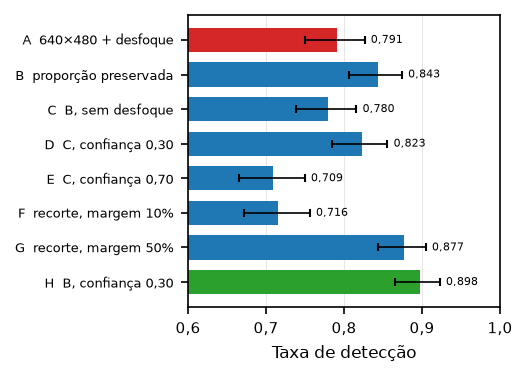

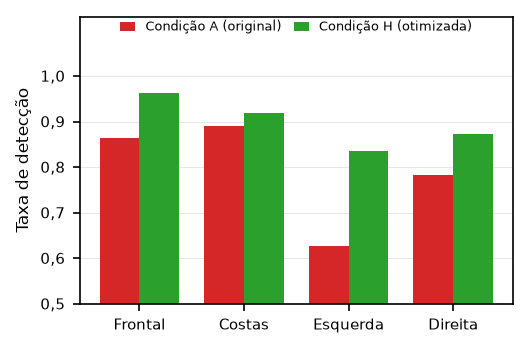

Por orientação, condição A: {'Costas': 0.891, 'Frontal': 0.864, 'Esquerda': 0.627, 'Direita': 0.782}
Por orientação, condição H: {'Costas': 0.918, 'Frontal': 0.964, 'Esquerda': 0.836, 'Direita': 0.873}


In [3]:
ORIENT_PT = {'front': 'Frontal', 'back': 'Costas', 'left': 'Esquerda', 'right': 'Direita'}
ROTULO_COND = {
    'A_atual': 'A  640$\\times$480 + desfoque', 'B_proporcao': 'B  proporção preservada',
    'C_sem_blur': 'C  B, sem desfoque', 'D_conf030': 'D  C, confiança 0,30',
    'D_conf070': 'E  C, confiança 0,70', 'E_bbox': 'F  recorte, margem 10%',
    'G_bbox_larga': 'G  recorte, margem 50%', 'F_melhor': 'H  B, confiança 0,30',
}


def figura_deteccao_condicoes(abl):
    """Fig. 2(a): taxa de detecção por condição, com IC95% de Wilson."""
    ordem = list(reversed(list(ROTULO_COND)))          # melhor condição (H) no topo
    taxas = [abl[c]['taxa_global'] for c in ordem]
    ics = [abl[c]['ic95_global'] for c in ordem]
    erros = np.array([[t - lo for t, (lo, hi) in zip(taxas, ics)],
                      [hi - t for t, (lo, hi) in zip(taxas, ics)]])
    cores = ['tab:red' if c == 'A_atual' else 'tab:green' if c == 'F_melhor' else 'tab:blue' for c in ordem]

    fig, ax = plt.subplots(figsize=(3.4, 2.4))
    y = np.arange(len(ordem))
    ax.barh(y, taxas, xerr=erros, color=cores, capsize=2, height=0.7, error_kw={'linewidth': 0.8})
    ax.set_yticks(y)
    ax.set_yticklabels([ROTULO_COND[c] for c in ordem], fontsize=6)
    ax.set_xlabel('Taxa de detecção', fontsize=8)
    ax.set_xlim(0.6, 1.0)
    ax.set_xticks([0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_xticklabels(['0,6', '0,7', '0,8', '0,9', '1,0'], fontsize=7)
    ax.grid(axis='x', alpha=0.3, linewidth=0.5)
    ax.set_axisbelow(True)
    for i, (t, (lo, hi)) in enumerate(zip(taxas, ics)):
        ax.text(hi + 0.008, i, virgula(t), va='center', fontsize=5.5)
    fig.tight_layout(pad=0.3)
    fig.savefig(os.path.join(DIR_FIGURAS, 'deteccao_condicoes.png'), dpi=300)
    return fig


def figura_deteccao_orientacao(abl):
    """Fig. 2(b): taxa de detecção por orientação da mão, condições A e H."""
    orients = ['front', 'back', 'left', 'right']
    x, largura = np.arange(len(orients)), 0.38
    fig, ax = plt.subplots(figsize=(3.4, 2.2))
    ax.bar(x - largura / 2, [abl['A_atual']['por_orientacao'][o]['taxa'] for o in orients], largura,
           label='Condição A (original)', color='tab:red')
    ax.bar(x + largura / 2, [abl['F_melhor']['por_orientacao'][o]['taxa'] for o in orients], largura,
           label='Condição H (otimizada)', color='tab:green')
    ax.set_xticks(x)
    ax.set_xticklabels([ORIENT_PT[o] for o in orients], fontsize=7)
    ax.set_ylabel('Taxa de detecção', fontsize=8)
    ax.set_ylim(0.5, 1.13)
    ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_yticklabels(['0,5', '0,6', '0,7', '0,8', '0,9', '1,0'], fontsize=7)
    ax.legend(fontsize=6, loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.03),
              handlelength=1.2, columnspacing=1.0)
    ax.grid(axis='y', alpha=0.3, linewidth=0.5)
    ax.set_axisbelow(True)
    fig.tight_layout(pad=0.3)
    fig.savefig(os.path.join(DIR_FIGURAS, 'deteccao_orientacao.png'), dpi=300)
    return fig


figura_deteccao_condicoes(ablacao)
figura_deteccao_orientacao(ablacao)
plt.show()

print('Por orientação, condição A:', {ORIENT_PT[o]: round(v['taxa'], 3) for o, v in ablacao['A_atual']['por_orientacao'].items()})
print('Por orientação, condição H:', {ORIENT_PT[o]: round(v['taxa'], 3) for o, v in ablacao['F_melhor']['por_orientacao'].items()})

## 3. Extração dos pontos-chave (condições A e H)

Os pontos-chave dos três splits são extraídos uma única vez para a união das 11 classes e guardados em
`resultados/landmarks_condA.npz` (pipeline de referência) e `resultados/landmarks_condH.npz` (melhor condição).
Cada arquivo tem, por split, `X` (63 coordenadas, zeros quando a mão não foi detectada), `y` (código da classe)
e `ok` (se o MediaPipe detectou a mão), na ordem das anotações COCO.

In [4]:
def extrair_landmarks(cond):
    import mediapipe as mp
    maos = mp.solutions.hands.Hands(static_image_mode=True, max_num_hands=1,
                                    min_detection_confidence=cond['conf'])
    saida = {}
    for split in ['train', 'val', 'test']:
        X, y, ok = [], [], []
        for item in carregar_split(split):
            imagem = cv2.imread(os.path.join(DIR_DATASET, item['arquivo']))
            res = maos.process(preparar_imagem(imagem, cond, item['bbox']))
            if res.multi_hand_landmarks:
                X.append([c for p in res.multi_hand_landmarks[0].landmark for c in (p.x, p.y, p.z)])
                ok.append(True)
            else:
                X.append([0.0] * 63)
                ok.append(False)
            y.append(item['codigo'])
        saida[f'{split}_X'] = np.array(X, dtype=np.float32)
        saida[f'{split}_y'] = np.array(y)
        saida[f'{split}_ok'] = np.array(ok)
        print(f"  {split}: {len(y)} imagens, detecção {np.mean(ok):.4f}")
    maos.close()
    return saida


if EXECUTAR_LANDMARKS:
    for nome, chave in [('condA', 'A_atual'), ('condH', 'F_melhor')]:
        print(nome)
        np.savez_compressed(os.path.join(DIR_RESULTADOS, f'landmarks_{nome}.npz'), **extrair_landmarks(CONDICOES[chave]))

LANDMARKS = {nome: dict(np.load(os.path.join(DIR_RESULTADOS, f'landmarks_{nome}.npz'))) for nome in ['condA', 'condH']}
for nome, d in LANDMARKS.items():
    print(nome, {s: f"{d[f'{s}_ok'].mean():.4f} de {len(d[f'{s}_y'])}" for s in ['train', 'val', 'test']})

condA {'train': '0.7977 de 4400', 'val': '0.8182 de 440', 'test': '0.7909 de 440'}
condH {'train': '0.8968 de 4400', 'val': '0.9045 de 440', 'test': '0.8977 de 440'}


## 4. Ramo geométrico: MLP

MLP com 128 unidades ReLU, *dropout* 0,5, 64 unidades ReLU e saída *softmax*; Adam, 20 épocas, lote 32,
sem aumento de dados, sem parada antecipada e sem busca de arquitetura (Seção III-E). Cinco sementes por configuração.

Duas representações (Seção III-B):
* **bruta**: as 63 coordenadas do MediaPipe (x e y normalizados pela imagem, então o MLP aprende em parte *onde* a mão está);
* **normalizada**: transladada para o pulso (ponto 0) e escalada pela norma máxima.

Para cada semente guardamos também a predição do MLP **em todas as imagens de teste do cenário**, com `-1` nas
imagens não detectadas. Essas predições alimentam o teste de McNemar e a matriz de confusão.

In [5]:
def normalizar(X):
    """Translada para o pulso (landmark 0) e escala pela norma máxima: sobra só a geometria da configuração."""
    P = X.reshape(-1, 21, 3).copy()
    P = P - P[:, 0:1, :]
    escala = np.linalg.norm(P, axis=2).max(axis=1, keepdims=True)[:, :, None]
    escala[escala == 0] = 1.0
    return (P / escala).reshape(-1, 63)


def construir_mlp(n_classes):
    return models.Sequential([
        layers.Input(shape=(63,)),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(64, activation='relu'),
        layers.Dense(n_classes, activation='softmax'),
    ])


def treinar_mlp(cond, cenario, representacao, semente):
    """Treina o MLP em um cenário e devolve (acurácia nas detectadas, predição em todas as imagens de teste)."""
    d, classes = LANDMARKS[cond], CENARIOS[cenario]
    dados = {}
    for split in ['train', 'val', 'test']:
        no_cenario = np.isin(d[f'{split}_y'], classes)
        sel = no_cenario & d[f'{split}_ok']                       # só as imagens com mão detectada
        X = d[f'{split}_X'][sel]
        X = normalizar(X) if representacao == 'normalizado' else X
        dados[split] = (X, np.array([classes.index(c) for c in d[f'{split}_y'][sel]]))
        if split == 'test':
            detectado = d['test_ok'][no_cenario]

    tf.keras.utils.set_random_seed(semente)
    modelo = construir_mlp(len(classes))
    modelo.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    modelo.fit(*dados['train'], validation_data=dados['val'], epochs=20, batch_size=32, verbose=0)
    pred = modelo.predict(dados['test'][0], verbose=0).argmax(axis=1)
    tf.keras.backend.clear_session()

    rel = classification_report(dados['test'][1], pred, output_dict=True, zero_division=0)
    pred_completa = np.full(len(detectado), -1)                   # -1 = mão não detectada
    pred_completa[detectado] = pred
    return rel['accuracy'], rel['macro avg']['f1-score'], pred_completa


# Configurações do artigo: condição A só com a representação bruta (pipeline de referência);
# condição H com as duas representações.
CONFIG_MLP = [('condA', 'bruto'), ('condH', 'bruto'), ('condH', 'normalizado')]
mlp = {}
t0 = time.time()
for cond, rep in CONFIG_MLP:
    for cen, classes in CENARIOS.items():
        accs, f1s = [], []
        for s in SEMENTES:
            acc, f1, pred = treinar_mlp(cond, cen, rep, s)
            accs.append(acc)
            f1s.append(f1)
            np.save(os.path.join(DIR_PRED, f'pred_{cen}_MLP_{cond}_{rep}_s{s}.npy'), pred)
        n_cen = int(np.isin(LANDMARKS[cond]['test_y'], classes).sum())
        taxa = float(LANDMARKS[cond]['test_ok'][np.isin(LANDMARKS[cond]['test_y'], classes)].mean())
        mlp[f'{cond}|{rep}|{cen}'] = {
            'condicao': cond, 'representacao': rep, 'cenario': cen, 'sementes': SEMENTES,
            'acuracias_cond_deteccao': accs, 'macro_f1s': f1s,
            'acc_cond_media': float(np.mean(accs)), 'acc_cond_std': float(np.std(accs)),
            'taxa_deteccao': taxa, 'n_teste': n_cen,
            # acurácia fim-a-fim = taxa de detecção x acurácia nas detectadas (falha de detecção conta como erro)
            'acc_fim_a_fim_media': float(np.mean(accs)) * taxa,
            'acc_fim_a_fim_std': float(np.std(np.array(accs) * taxa)),
        }
salvar_json(mlp, 'mlp.json')
print(f'{len(CONFIG_MLP) * len(CENARIOS) * len(SEMENTES)} MLPs treinados em {time.time() - t0:.0f} s')

pd.DataFrame(mlp).T[['condicao', 'representacao', 'cenario', 'taxa_deteccao', 'acc_cond_media',
                     'acc_cond_std', 'acc_fim_a_fim_media']].round(3)

45 MLPs treinados em 252 s


,condicao,representacao,cenario,taxa_deteccao,acc_cond_media,acc_cond_std,acc_fim_a_fim_media
condA|bruto|5_classes,condA,bruto,5_classes,0.77,0.980519,0.012987,0.755
condA|bruto|6_classes,condA,bruto,6_classes,0.7625,0.856831,0.013996,0.653333
condA|bruto|10_classes,condA,bruto,10_classes,0.7975,0.861442,0.019964,0.687
condH|bruto|5_classes,condH,bruto,5_classes,0.88,0.940909,0.007707,0.828
condH|bruto|6_classes,condH,bruto,6_classes,0.8875,0.822535,0.014363,0.73
condH|bruto|10_classes,condH,bruto,10_classes,0.895,0.841341,0.022094,0.753
condH|normalizado|5_classes,condH,normalizado,5_classes,0.88,0.956818,0.005794,0.842
condH|normalizado|6_classes,condH,normalizado,6_classes,0.8875,0.877934,0.018779,0.779167
condH|normalizado|10_classes,condH,normalizado,10_classes,0.895,0.905028,0.007284,0.81


**Conferência com os resultados originais.** Os MLPs acima foram retreinados agora. A célula abaixo compara as
médias com as que estão no artigo (arquivos `multiplas_sementes_mlp.json` e `mlp_condicao_otimizada.json`,
gerados pelos scripts originais). Diferenças na terceira casa podem aparecer em outra GPU ou outra versão do
TensorFlow, porque o treino na GPU não é bit a bit determinístico.

In [6]:
orig_A = carregar_json('multiplas_sementes_mlp.json')
orig_H = carregar_json('mlp_condicao_otimizada.json')
conf = []
for cen in CENARIOS:
    conf.append({'config': f'A bruto {cen}', 'original': orig_A[cen]['acuracia_media'],
                 'reproduzido': mlp[f'condA|bruto|{cen}']['acc_cond_media']})
    for rep in ['bruto', 'normalizado']:
        conf.append({'config': f'H {rep} {cen}', 'original': orig_H[f'{cen}|{rep}']['acuracia_media'],
                     'reproduzido': mlp[f'condH|{rep}|{cen}']['acc_cond_media']})
conf = pd.DataFrame(conf).set_index('config')
conf['diferença'] = conf['reproduzido'] - conf['original']
conf.round(4)

,original,reproduzido,diferença
config,,,
A bruto 5_classes,0.9805,0.9805,0.0
H bruto 5_classes,0.9409,0.9409,0.0
H normalizado 5_classes,0.9568,0.9568,0.0
A bruto 6_classes,0.8568,0.8568,0.0
H bruto 6_classes,0.8225,0.8225,0.0
H normalizado 6_classes,0.8779,0.8779,0.0
A bruto 10_classes,0.8614,0.8614,0.0
H bruto 10_classes,0.8413,0.8413,0.0
H normalizado 10_classes,0.9050,0.9050,0.0


### Tabela I: efeito de seleção (5 classes, representação bruta)

Melhorar o detector (A → H) faz a acurácia condicionada à detecção **cair**, enquanto a acurácia fim-a-fim sobe.
As imagens que passam a ser detectadas são as mais difíceis (vistas laterais, poses ambíguas).

In [7]:
tab1 = pd.DataFrame([{
    'Condição': nome,
    'Detecção': mlp[f'{c}|bruto|5_classes']['taxa_deteccao'],
    'Acur. cond. à detecção': mlp[f'{c}|bruto|5_classes']['acc_cond_media'],
    'Acur. fim-a-fim': mlp[f'{c}|bruto|5_classes']['acc_fim_a_fim_media'],
} for nome, c in [('A (referência)', 'condA'), ('H (otimizada)', 'condH')]]).set_index('Condição')
display(tab1.round(3))

d = tab1.diff().iloc[1]
print(f"Acurácia condicionada: {100 * d['Acur. cond. à detecção']:+.1f} p.p. | "
      f"fim-a-fim: {100 * d['Acur. fim-a-fim']:+.1f} p.p. | detecção: {100 * d['Detecção']:+.1f} p.p.")

,Detecção,Acur. cond. à detecção,Acur. fim-a-fim
Condição,,,
A (referência),0.77,0.981,0.755
H (otimizada),0.88,0.941,0.828


Acurácia condicionada: -4.0 p.p. | fim-a-fim: +7.3 p.p. | detecção: +11.0 p.p.


### Representação dos landmarks (Seção IV-B)

A normalização pelo pulso melhora o MLP, tanto mais quanto mais difícil o cenário. As comparações seguintes
usam a representação normalizada na condição H.

In [8]:
pd.DataFrame({rep: {cen: mlp[f'condH|{rep}|{cen}']['acc_cond_media'] for cen in CENARIOS}
              for rep in ['bruto', 'normalizado']}).round(3)

,bruto,normalizado
5_classes,0.941,0.957
6_classes,0.823,0.878
10_classes,0.841,0.905


## 5. Armadilha 2: backbone congelado, ablação em escada da ResNet50 (Seção IV-C, Tabela II)

No protocolo de referência, a ResNet50 congelada e a ajustada não diferem só pelo congelamento: a ajustada também
recebe aumento de dados, mais épocas e embaralhamento. Como as anotações do LSWH100 vêm agrupadas por classe,
treinar sem embaralhamento com lotes de 16 produz lotes com apenas duas classes.

A escada separa os fatores (5 sementes por degrau, 75 treinos):

| Degrau | Backbone | Embaralhamento | Aumento | Épocas (paciência) | LR |
|---|---|---|---|---|---|
| C0 | congelado | não | não | 10 (3) | 1e-4 |
| C1 | congelado | sim | não | 10 (3) | 1e-4 |
| C2 | congelado | sim | sim | 30 (6) | 1e-4 |
| C2b | congelado | sim | sim | 30 (6) | 1e-5 |
| C3 | `conv5_*` treinável | sim | sim | 30 (6) | 1e-5 |

O código do treino está em [`experimentos/resnet50_escada.py`](experimentos/resnet50_escada.py). Cada treino roda num
subprocesso, porque encadear dezenas de treinos da ResNet50 no mesmo processo vaza memória.

In [9]:
DEGRAUS = ['C0_original', 'C1_shuffle', 'C2_protocolo', 'C2b_lr_baixo', 'C3_finetuning']

if EXECUTAR_RESNET:
    for cen in CENARIOS:
        for degrau in DEGRAUS:
            for s in SEMENTES:
                subprocess.run([sys.executable, os.path.join('experimentos', 'resnet50_escada.py'),
                                cen, degrau, str(s), '--dataset', DIR_DATASET, '--saida', DIR_RESULTADOS],
                               check=True)

escada = carregar_json('ablacao_escada_treino.json')


def media_dp(cen, degrau):
    a = [x['acuracia_teste'] for x in escada[cen][degrau]]
    return float(np.mean(a)), float(np.std(a))


ROTULO_DEGRAU = {'C0_original': 'C0 protocolo original', 'C1_shuffle': 'C1 + embaralhamento',
                 'C2_protocolo': 'C2 + aumento e orçamento', 'C3_finetuning': 'C3 + descongelamento',
                 'C2b_lr_baixo': 'C2b (C2 com LR 1e-5)'}
tab2 = pd.DataFrame({cen.replace('_classes', ' cl.'): {ROTULO_DEGRAU[g]: '{} ± {}'.format(*map(virgula, media_dp(cen, g)))
                                                    for g in DEGRAUS}
                     for cen in CENARIOS})
tab2

,5 cl.,6 cl.,10 cl.
C0 protocolo original,"0,803 ± 0,015","0,714 ± 0,022","0,614 ± 0,009"
C1 + embaralhamento,"0,820 ± 0,018","0,744 ± 0,019","0,643 ± 0,010"
C2 + aumento e orçamento,"0,846 ± 0,006","0,780 ± 0,015","0,688 ± 0,012"
C2b (C2 com LR 1e-5),"0,747 ± 0,013","0,642 ± 0,031","0,516 ± 0,011"
C3 + descongelamento,"0,980 ± 0,008","0,952 ± 0,012","0,947 ± 0,003"


In [10]:
# Decomposição citada no texto: quanto vem do protocolo de treino (C0 -> C2) e quanto do descongelamento (C2 -> C3).
decomp = {}
for cen in CENARIOS:
    c0, c2, c3 = (round(media_dp(cen, g)[0], 3) for g in ['C0_original', 'C2_protocolo', 'C3_finetuning'])
    protocolo, descong = 100 * (c2 - c0), 100 * (c3 - c2)
    decomp[cen] = {'protocolo (p.p.)': protocolo, 'descongelamento (p.p.)': descong,
                   'total C0→C3 (p.p.)': protocolo + descong,
                   'fração do descongelamento': descong / (protocolo + descong)}
pd.DataFrame(decomp).T.round(3)

,protocolo (p.p.),descongelamento (p.p.),total C0→C3 (p.p.),fração do descongelamento
5_classes,4.3,13.4,17.7,0.757
6_classes,6.6,17.2,23.8,0.723
10_classes,7.4,25.9,33.3,0.778


## 6. Teste de McNemar pareado (Seções IV-C e IV-D)

Todos os modelos são avaliados nas mesmas imagens de teste, então a comparação é feita com o teste de McNemar
exato (binomial), pareado por imagem, para cada semente. Convenção fim-a-fim: uma imagem em que o MediaPipe falhou
conta como erro do MLP.

In [11]:
def acertos(cen, modelo, s):
    y = np.load(os.path.join(DIR_PRED, f'y_{cen}.npy'))
    if modelo == 'MLP':
        pred = np.load(os.path.join(DIR_PRED, f'pred_{cen}_MLP_condH_normalizado_s{s}.npy'))
    else:
        pred = np.load(os.path.join(DIR_PRED, f'pred_{cen}_{modelo}_s{s}.npy'))
    return pred == y


def mcnemar(a, b):
    """McNemar exato. a, b: vetores booleanos de acerto nas mesmas imagens."""
    n01, n10 = int(np.sum(a & ~b)), int(np.sum(~a & b))
    p = 1.0 if n01 + n10 == 0 else binomtest(n01, n01 + n10, 0.5).pvalue
    return n01, n10, float(p)


# Os rótulos de teste da ResNet (y_*.npy) e do MLP seguem a mesma ordem das anotações COCO.
for cen, classes in CENARIOS.items():
    y_mlp = np.array([classes.index(c) for c in LANDMARKS['condH']['test_y'] if c in classes])
    assert np.array_equal(y_mlp, np.load(os.path.join(DIR_PRED, f'y_{cen}.npy'))), 'ordem de teste diferente'

COMPARACOES = [('MLP', 'C2_protocolo'), ('MLP', 'C3_finetuning'), ('C2_protocolo', 'C3_finetuning')]
mc = {}
for cen in CENARIOS:
    for a, b in COMPARACOES:
        ps = [mcnemar(acertos(cen, a, s), acertos(cen, b, s))[2] for s in SEMENTES]
        mc[(cen, f'{a} vs {b}')] = {'p mín.': f'{min(ps):.2e}', 'p máx.': f'{max(ps):.2e}',
                                    'sementes com p<0,05': sum(p < 0.05 for p in ps)}
salvar_json({f'{c}|{k}': v for (c, k), v in mc.items()}, 'mcnemar.json')
pd.DataFrame(mc).T

p mín.    p máx.  \
5_classes  MLP vs C2_protocolo            7.80e-01  1.00e+00   
           MLP vs C3_finetuning           3.73e-09  6.62e-05   
           C2_protocolo vs C3_finetuning  1.49e-08  4.65e-06   
6_classes  MLP vs C2_protocolo            2.82e-01  9.11e-01   
           MLP vs C3_finetuning           5.91e-12  1.24e-06   
           C2_protocolo vs C3_finetuning  8.36e-12  7.60e-09   
10_classes MLP vs C2_protocolo            2.87e-06  1.09e-03   
           MLP vs C3_finetuning           1.39e-11  1.35e-08   
           C2_protocolo vs C3_finetuning  4.63e-29  1.25e-23   

                                         sementes com p<0,05  
5_classes  MLP vs C2_protocolo                             0  
           MLP vs C3_finetuning                            5  
           C2_protocolo vs C3_finetuning                   5  
6_classes  MLP vs C2_protocolo                             0  
           MLP vs C3_finetuning                            5  
           C2_protocolo vs C3_finetuning                   5  
10_classes MLP vs C2_protocolo                             5  
           MLP vs C3_finetuning                            5  
           C2_protocolo vs C3_finetuning                   5

Leitura:
* MLP × ResNet50 congelada (C2): sem diferença significativa com 5 e 6 classes; com 10 classes o MLP é superior.
* MLP × ResNet50 ajustada (C3): o MLP é inferior nos três cenários, em todas as sementes.
* C2 × C3: o efeito do descongelamento sobrevive à equalização do protocolo, em todas as sementes.

## 7. Comparação fim-a-fim (Tabela III)

In [12]:
tab3 = {}
for cen in CENARIOS:
    r = mlp[f'condH|normalizado|{cen}']
    tab3[cen.replace('_', ' ')] = {
        'MLP cond. à detecção': f"{virgula(r['acc_cond_media'])} ± {virgula(r['acc_cond_std'])}",
        'MLP fim-a-fim': f"{virgula(r['acc_fim_a_fim_media'])} ± {virgula(r['acc_fim_a_fim_std'])}",
        'R50 cong. (C2)': '{} ± {}'.format(*map(virgula, media_dp(cen, 'C2_protocolo'))),
        'R50 f.t. (C3)': '{} ± {}'.format(*map(virgula, media_dp(cen, 'C3_finetuning'))),
    }
pd.DataFrame(tab3).T

,MLP cond. à detecção,MLP fim-a-fim,R50 cong. (C2),R50 f.t. (C3)
5 classes,"0,957 ± 0,006","0,842 ± 0,005","0,846 ± 0,006","0,980 ± 0,008"
6 classes,"0,878 ± 0,019","0,779 ± 0,017","0,780 ± 0,015","0,952 ± 0,012"
10 classes,"0,905 ± 0,007","0,810 ± 0,007","0,688 ± 0,012","0,947 ± 0,003"


**Esforço desigual entre os ramos (resposta ao revisor).** O MLP não teve aumento de dados, parada antecipada nem
busca de arquitetura. Isso não muda a conclusão: como as imagens não detectadas contam como erro, a acurácia
fim-a-fim do MLP não passa da taxa de detecção na condição H, que já fica abaixo da ResNet50 ajustada.
Mesmo um MLP perfeito nas imagens detectadas perderia a comparação.

In [13]:
limite = pd.DataFrame({cen: {'teto do MLP (= detecção em H)': mlp[f'condH|normalizado|{cen}']['taxa_deteccao'],
                             'R50 f.t. (C3)': media_dp(cen, 'C3_finetuning')[0]} for cen in CENARIOS}).T
limite['folga da R50'] = limite['R50 f.t. (C3)'] - limite['teto do MLP (= detecção em H)']
limite.round(3)

,teto do MLP (= detecção em H),R50 f.t. (C3),folga da R50
5_classes,0.880,0.980,0.100
6_classes,0.888,0.952,0.064
10_classes,0.895,0.947,0.052


**Limitação (resposta ao revisor).** No LSWH100 a mão já vem única e centralizada, então o ramo de pixels não
precisa de detector. Para dar a ordem de grandeza: se um detector para o ramo de pixels falhasse tanto quanto o
MediaPipe na condição H, a ResNet50 ajustada ficaria em torno de:

In [14]:
estim = pd.DataFrame({cen: {
    'R50 f.t. x detecção em H': media_dp(cen, 'C3_finetuning')[0] * mlp[f'condH|normalizado|{cen}']['taxa_deteccao'],
    'MLP fim-a-fim': mlp[f'condH|normalizado|{cen}']['acc_fim_a_fim_media'],
} for cen in CENARIOS}).T
estim['margem (p.p.)'] = 100 * (estim['R50 f.t. x detecção em H'] - estim['MLP fim-a-fim'])
estim.round(3)

,R50 f.t. x detecção em H,MLP fim-a-fim,margem (p.p.)
5_classes,0.862,0.842,2.040
6_classes,0.845,0.779,6.544
10_classes,0.848,0.810,3.756


## 8. Matrizes de confusão, 5 classes (Fig. 3)

Somadas sobre as cinco sementes: cada linha totaliza 200 imagens (40 de teste × 5 sementes). Os três painéis
cobrem as mesmas imagens; o MLP ganha a coluna "n.d." com as imagens não detectadas pelo MediaPipe.

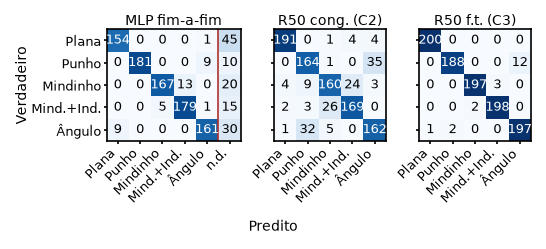

MLP fim-a-fim: acurácia fim-a-fim 0.842, não detectadas 120
R50 cong. (C2): acurácia fim-a-fim 0.846
R50 f.t. (C3): acurácia fim-a-fim 0.980


In [15]:
def matriz(cen, modelo, n):
    y = np.load(os.path.join(DIR_PRED, f'y_{cen}.npy'))
    colunas = n + 1 if modelo == 'MLP' else n
    cm = np.zeros((n, colunas), dtype=int)
    for s in SEMENTES:
        if modelo == 'MLP':
            pred = np.load(os.path.join(DIR_PRED, f'pred_{cen}_MLP_condH_normalizado_s{s}.npy'))
            pred = np.where(pred < 0, n, pred)                  # coluna n = não detectada
        else:
            pred = np.load(os.path.join(DIR_PRED, f'pred_{cen}_{modelo}_s{s}.npy'))
        np.add.at(cm, (y, pred), 1)
    return cm


def figura_confusao(paineis, nome_base):
    nomes = [NOMES_PT[c] for c in CLASSES_5]
    fig, axs = plt.subplots(1, 3, figsize=(3.5, 1.72), gridspec_kw={'width_ratios': [cm.shape[1] for _, cm in paineis]})
    for k, (ax, (titulo, cm)) in enumerate(zip(axs, paineis)):
        ax.imshow(cm, cmap='Blues', vmin=0, vmax=200)
        ax.set_xticks(range(cm.shape[1]))
        ax.set_xticklabels(nomes + (['n.d.'] if cm.shape[1] == 6 else []), rotation=45, ha='right', fontsize=6)
        ax.set_yticks(range(5))
        ax.set_yticklabels(nomes if k == 0 else [], fontsize=6)
        ax.set_title(titulo, fontsize=6.5, pad=2)
        ax.tick_params(length=1.5, pad=1)
        if cm.shape[1] == 6:
            ax.axvline(4.5, color='#b03030', linewidth=0.8)       # separa a coluna de falhas de detecção
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=6,
                        color='white' if cm[i, j] > 100 else 'black')
    axs[0].set_ylabel('Verdadeiro', fontsize=6.5, labelpad=1)
    fig.supxlabel('Predito', fontsize=6.5, y=0.015)
    fig.tight_layout(pad=0.2, w_pad=0.4, rect=(0, 0.03, 1, 1))
    fig.savefig(os.path.join(DIR_FIGURAS, nome_base + '.png'), dpi=600)
    with matplotlib.rc_context({'pdf.fonttype': 42}):
        fig.savefig(os.path.join(DIR_FIGURAS, nome_base + '.pdf'))
    return fig


paineis = [('MLP fim-a-fim', matriz('5_classes', 'MLP', 5)),
           ('R50 cong. (C2)', matriz('5_classes', 'C2_protocolo', 5)),
           ('R50 f.t. (C3)', matriz('5_classes', 'C3_finetuning', 5))]
figura_confusao(paineis, 'matrizes_confusao_5_classes')
plt.show()
for titulo, cm in paineis:
    print(f'{titulo}: acurácia fim-a-fim {np.trace(cm[:, :5]) / cm.sum():.3f}'
          + (f', não detectadas {cm[:, 5].sum()}' if cm.shape[1] == 6 else ''))

## 9. Latência de inferência (Seção IV-E, Tabela IV)

Dois protocolos, lote unitário:
* **classificador**: só a rede, como grafo `tf.function` compilado, em GPU (média de 200 execuções após 30 de aquecimento);
* **pipeline completo**: leitura da imagem do disco + pré-processamento + classificador (60 execuções após 10 de
  aquecimento). No ramo geométrico isso inclui o MediaPipe (CPU), com o pré-processamento do pipeline de referência.

Os pesos não alteram o tempo de inferência, então as redes são instanciadas com pesos aleatórios. A latência depende
do hardware: os números salvos são da RTX 4050 do artigo.

In [16]:
def bench(fn, n, aquecimento):
    for _ in range(aquecimento):
        fn()
    tempos = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        tempos.append(time.perf_counter() - t0)
    return float(np.mean(tempos) * 1000), float(np.std(tempos) * 1000)


if EXECUTAR_LATENCIA:
    import mediapipe as mp
    from tensorflow.keras.applications import ResNet50

    imagem_exemplo = os.path.join(DIR_DATASET, 'front', 'test', 'S15a_image.000000.rgb.png')
    maos = mp.solutions.hands.Hands(static_image_mode=True, max_num_hands=1, min_detection_confidence=0.5)

    mlp_rede = construir_mlp(5)
    cnn = models.Sequential([ResNet50(weights=None, include_top=False, input_shape=(224, 224, 3)),
                             layers.GlobalAveragePooling2D(), layers.Dense(256, activation='relu'),
                             layers.Dropout(0.5), layers.Dense(5, activation='softmax')])
    mlp_fn = tf.function(lambda x: mlp_rede(x, training=False))
    cnn_fn = tf.function(lambda x: cnn(x, training=False))
    x_mlp = tf.constant(np.random.rand(1, 63).astype('float32'))
    x_cnn = tf.constant(np.random.rand(1, 224, 224, 3).astype('float32'))

    def pipeline_mlp():
        rgb = preparar_imagem(cv2.imread(imagem_exemplo), CONDICOES['A_atual'])
        res = maos.process(rgb)
        if res.multi_hand_landmarks:
            v = [c for p in res.multi_hand_landmarks[0].landmark for c in (p.x, p.y, p.z)]
            mlp_fn(tf.constant([v], dtype=tf.float32)).numpy()

    def pipeline_cnn():
        img = tf.image.decode_png(tf.io.read_file(imagem_exemplo), channels=3)
        img = tf.keras.applications.resnet50.preprocess_input(tf.image.resize(img, [224, 224]))
        cnn_fn(tf.expand_dims(img, 0)).numpy()

    m1, d1 = bench(lambda: mlp_fn(x_mlp).numpy(), 200, 30)
    m2, d2 = bench(lambda: cnn_fn(x_cnn).numpy(), 200, 30)
    m3, d3 = bench(pipeline_mlp, 60, 10)
    m4, d4 = bench(pipeline_cnn, 60, 10)
    maos.close()
    salvar_json({'classificador_puro_ms': {'mlp_media': m1, 'mlp_std': d1, 'resnet50_media': m2, 'resnet50_std': d2,
                                           'razao_resnet50_sobre_mlp': m2 / m1},
                 'pipeline_completo_ms': {'mlp_media': m3, 'mlp_std': d3, 'resnet50_media': m4, 'resnet50_std': d4}},
                'latencia_final.json')

lat = carregar_json('latencia_final.json')
c, p = lat['classificador_puro_ms'], lat['pipeline_completo_ms']
display(pd.DataFrame({
    'Classificador (ms)': {'MLP (+ MediaPipe)': f"{virgula(c['mlp_media'], 2)} ± {virgula(c['mlp_std'], 2)}",
                           'ResNet50': f"{virgula(c['resnet50_media'], 2)} ± {virgula(c['resnet50_std'], 2)}"},
    'Pipeline completo (ms)': {'MLP (+ MediaPipe)': f"{virgula(p['mlp_media'], 2)} ± {virgula(p['mlp_std'], 2)}",
                               'ResNet50': f"{virgula(p['resnet50_media'], 2)} ± {virgula(p['resnet50_std'], 2)}"}}))
print(f"Classificador: MLP {c['resnet50_media'] / c['mlp_media']:.0f}x mais rápido | "
      f"pipeline completo: ResNet50 {p['mlp_media'] / p['resnet50_media']:.1f}x mais rápida")

,Classificador (ms),Pipeline completo (ms)
MLP (+ MediaPipe),"0,22 ± 0,02","24,50 ± 0,76"
ResNet50,"6,40 ± 0,43","10,79 ± 0,65"


Classificador: MLP 30x mais rápido | pipeline completo: ResNet50 2.3x mais rápida


## 10. Robustez à versão do MediaPipe (Seção IV-E, último parágrafo)

A API `mp.solutions.hands` usada no pipeline de referência foi removida no MediaPipe 1.0.0. A taxa de detecção das
condições A e H foi medida de novo com a API `tasks` (`HandLandmarker`) nas versões 0.10.21 e 1.0.1.

Para refazer com a versão instalada, ligue `EXECUTAR_VERSOES_MP`. O modelo `hand_landmarker.task` é baixado do
repositório oficial do MediaPipe. Para medir a versão 1.0.1, rode o notebook num ambiente com `mediapipe==1.0.1`
(a API `solutions` não existe nessa versão e é pulada automaticamente).

In [17]:
URL_TASK = ('https://storage.googleapis.com/mediapipe-models/hand_landmarker/'
            'hand_landmarker/float16/1/hand_landmarker.task')


def detector_tasks(conf):
    import urllib.request
    import mediapipe as mp
    from mediapipe.tasks import python as mp_python
    from mediapipe.tasks.python import vision
    caminho = os.path.join('modelos', 'hand_landmarker.task')
    if not os.path.exists(caminho):
        os.makedirs('modelos', exist_ok=True)
        urllib.request.urlretrieve(URL_TASK, caminho)
    opcoes = vision.HandLandmarkerOptions(base_options=mp_python.BaseOptions(model_asset_path=caminho),
                                          running_mode=vision.RunningMode.IMAGE, num_hands=1,
                                          min_hand_detection_confidence=conf, min_hand_presence_confidence=conf)
    lm = vision.HandLandmarker.create_from_options(opcoes)
    return (lambda rgb: len(lm.detect(mp.Image(image_format=mp.ImageFormat.SRGB,
                                               data=np.ascontiguousarray(rgb))).hand_landmarks) > 0), lm.close


def detector_solutions(conf):
    import mediapipe as mp
    maos = mp.solutions.hands.Hands(static_image_mode=True, max_num_hands=1, min_detection_confidence=conf)
    return (lambda rgb: bool(maos.process(rgb).multi_hand_landmarks)), maos.close


if EXECUTAR_VERSOES_MP:
    import mediapipe as mp
    versoes = carregar_json('comparacao_versoes_mediapipe.json')
    itens_teste = carregar_split('test')
    apis = [('moderna_tasks', detector_tasks)]
    if hasattr(mp, 'solutions'):
        apis.insert(0, ('legada_solutions', detector_solutions))
    for chave in ['A_atual', 'F_melhor']:
        cond = CONDICOES[chave]
        for nome_api, fabrica in apis:
            detecta, fechar = fabrica(cond['conf'])
            ok = [detecta(preparar_imagem(cv2.imread(os.path.join(DIR_DATASET, it['arquivo'])), cond))
                  for it in itens_teste]
            fechar()
            versoes[f'{chave}|{nome_api}|mp{mp.__version__}'] = {
                'total': len(ok), 'detectado': int(sum(ok)), 'taxa_global': float(np.mean(ok)),
                'ic95_global': list(wilson(int(sum(ok)), len(ok)))}
    salvar_json(versoes, 'comparacao_versoes_mediapipe.json')

versoes = carregar_json('comparacao_versoes_mediapipe.json')
pd.DataFrame([{'Condição': CONDICOES[k.split('|')[0]]['artigo'], 'API': k.split('|')[1],
               'MediaPipe': k.split('|')[2][2:], 'Taxa de detecção': v['taxa_global'], 'Detectadas': v['detectado']}
              for k, v in versoes.items()]).sort_values(['Condição', 'MediaPipe']).round(3)

,Condição,API,MediaPipe,Taxa de detecção,Detectadas
0,A,legada_solutions,0.10.21,0.791,348
1,A,moderna_tasks,0.10.21,0.791,348
4,A,moderna_tasks,1.0.1,0.791,348
2,H,legada_solutions,0.10.21,0.898,395
3,H,moderna_tasks,0.10.21,0.905,398
5,H,moderna_tasks,1.0.1,0.905,398


## 11. Resumo: números citados no texto

A célula abaixo junta, num só lugar, os números do resumo e da conclusão do artigo calculados a partir dos
resultados acima.

In [18]:
H5 = mlp['condH|normalizado|5_classes']
resumo = {
    'Detecção global A → H': f"{virgula(ablacao['A_atual']['taxa_global'])} → {virgula(ablacao['F_melhor']['taxa_global'])}",
    'Tabela I, 5 cl.: detecção A → H': f"{virgula(tab1.iloc[0, 0])} → {virgula(tab1.iloc[1, 0])}",
    'Tabela I, 5 cl.: acur. condicionada A → H': f"{virgula(tab1.iloc[0, 1])} → {virgula(tab1.iloc[1, 1])}",
    'Tabela I, 5 cl.: acur. fim-a-fim A → H': f"{virgula(tab1.iloc[0, 2])} → {virgula(tab1.iloc[1, 2])}",
    'Ganho do descongelamento (C2 → C3), p.p.': ', '.join(virgula(v['descongelamento (p.p.)'], 1) for v in decomp.values()),
    'Ganho do protocolo (C0 → C2), p.p.': ', '.join(virgula(v['protocolo (p.p.)'], 1) for v in decomp.values()),
    'Custo da métrica no MLP (cond. − fim-a-fim), p.p.': ', '.join(
        virgula(100 * (mlp[f'condH|normalizado|{c}']['acc_cond_media'] - mlp[f'condH|normalizado|{c}']['acc_fim_a_fim_media']), 1)
        for c in CENARIOS),
    'Pipeline completo: ResNet50 mais rápida': f"{p['mlp_media'] / p['resnet50_media']:.1f}x",
}
pd.Series(resumo, name='valor').to_frame()

,valor
Detecção global A → H,"0,791 → 0,898"
"Tabela I, 5 cl.: detecção A → H","0,770 → 0,880"
"Tabela I, 5 cl.: acur. condicionada A → H","0,981 → 0,941"
"Tabela I, 5 cl.: acur. fim-a-fim A → H","0,755 → 0,828"
"Ganho do descongelamento (C2 → C3), p.p.","13,4, 17,2, 25,9"
"Ganho do protocolo (C0 → C2), p.p.","4,3, 6,6, 7,4"
"Custo da métrica no MLP (cond. − fim-a-fim), p.p.","11,5, 9,9, 9,5"
Pipeline completo: ResNet50 mais rápida,2.3x
